# Importing Libraries

In [3]:
!pip install torch_geometric
!pip install rdkit
import torch
import torch.nn as nn
from torch_geometric.nn import GCNConv, global_mean_pool
import pandas as pd
from torch_geometric.data import Data, Batch
from rdkit import Chem
from rdkit.Chem import AllChem

In [4]:
# 1. Load datasets
df_release = pd.read_csv('smart_nano_cleaned.csv')
df_phyto = pd.read_csv('/content/phytochemical_dictionary_final.csv')

# Percentage composition (approximate weights)
composition_weights = {
    "2, 6-Octadienal, 3, 7-dimethyl-(Z)": 12.40,
    "Citral": 18.98,
    "Cis-3-Hexenyl cis-3-hexenoate": 10.76,
    "Trans-2, 7-Dimethyl-4, 6-octadien-2-ol": 20.52,
    "3,8,11-Trioxatetracyclo[4.4.1.0(2,4).0(7,9)]undecane (1α,2α,4α,6α,7β,9β)": 3.32,
    "3-Hexene, 2-methyl-(Z)-": 3.72,
    "Hexadecanoic acid, methyl ester": 3.50,
    "n-Hexadecanoic acid": 5.30,
    "cis-Vaccenic acid": 4.90,
    "6, 11-Dimethyl-2, 6, 10-dedecatrien-1-ol": 2.72,
    "Heptadecanoic acid, 16-methyl-, methyl ester": 2.49,
    "9, 17-Octadecadienal, (Z)-": 7.75,
    "Oleic Acid": 3.42
}
def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if not mol: return None
    # Node features: Atomic number, hybridization, aromaticity
    atoms = [[a.GetAtomicNum(), a.GetHybridization().real, float(a.GetIsAromatic())] for a in mol.GetAtoms()]
    x = torch.tensor(atoms, dtype=torch.float)
    # Edges: Bonds
    edges = []
    for bond in mol.GetBonds():
        edges.extend([[bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()], [bond.GetEndAtomIdx(), bond.GetBeginAtomIdx()]])
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(x=x, edge_index=edge_index)

# Generate graphs for all 13 molecules
phyto_graphs = {row['Name']: smiles_to_graph(row['SMILES']) for _, row in df_phyto.iterrows()}

## Define the PIGNN Model

In [5]:
class PIGNN(nn.Module):
    def __init__(self):
        super(PIGNN, self).__init__()
        # Chemistry Branch (Graph Neural Network)
        self.conv1 = GCNConv(3, 16)
        self.conv2 = GCNConv(16, 32)

        # Physics Fusion Branch
        self.fc = nn.Sequential(
            nn.Linear(32 + 3, 64), # 32 from Graph + 3 (Time, pH, Form)
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, graph_batch, env_data):
        # 1. Process Molecular Graphs
        x, edge_index, batch = graph_batch.x, graph_batch.edge_index, graph_batch.batch
        x = torch.relu(self.conv1(x, edge_index))
        x = torch.relu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)

        # 2. Combine with Physical environment (pH, Time, Form)
        combined = torch.cat([x, env_data], dim=1)
        return self.fc(combined)

model = PIGNN()
print("PIGNN Model Architecture Initialized.")

PIGNN Model Architecture Initialized.


## The Physics Informed Training

In [6]:
def physics_loss(pred, time, target):
    # Standard MSE Loss
    mse_loss = nn.MSELoss()(pred, target)

    # Physics Constraint (Korsmeyer-Peppas rule)
    # n=0.5 represents standard Fickian diffusion
    k, n = 0.1, 0.5
    theoretical = k * torch.pow(time + 1e-6, n)
    p_loss = torch.mean((pred - theoretical)**2)

    return mse_loss + 0.1 * p_loss

# Preparation for Training
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
# Formulation Encoding: Test=1, Control=0
df_release['Form_Binary'] = df_release['Formulation'].map({'Test': 1, 'Control': 0})

## The Training Loop

In [7]:
# --- FIX: DEFINE THE PHYSICS-INFORMED LOSS FUNCTION ---
def physics_informed_loss(pred, target, time, k=0.1, n=0.5):
    # 1. Standard Data Loss (Mean Squared Error)
    mse_loss = nn.MSELoss()(pred, target)

    # 2. Physics Constraint (Korsmeyer-Peppas Diffusion)
    # This ensures the model follows the laws of physics for drug release
    # n=0.5 represents Fickian diffusion
    theoretical_release = k * torch.pow(time + 1e-6, n)
    p_loss = torch.mean((pred - theoretical_release)**2)

    # 3. Combined Loss
    # We add a 0.1 weight to the physics penalty
    return mse_loss + 0.1 * p_loss

print(" Function 'physics_informed_loss' is now defined.")

 Function 'physics_informed_loss' is now defined.


In [8]:
#  WEIGHTED PIGNN TRAINING LOOP

# Normalize Environmental Data (helps the AI learn stable patterns)
times = torch.tensor(df_release['Time_h'].values, dtype=torch.float).view(-1, 1) / 96.0
phs = torch.tensor(df_release['pH'].values, dtype=torch.float).view(-1, 1) / 7.4
forms = torch.tensor(df_release['Form_Binary'].values, dtype=torch.float).view(-1, 1)
targets = torch.tensor(df_release['Release_Percent'].values, dtype=torch.float).view(-1, 1) / 100.0

# Create the "Control" Graph (Blank nanocarrier)
zero_x = torch.zeros((1, 3)) # No chemical features
zero_edge = torch.tensor([[0], [0]], dtype=torch.long)
control_graph = Batch.from_data_list([Data(x=zero_x, edge_index=zero_edge)])

# Create the "Test Extract" Batch and Weights
test_extract_graphs = []
weights_list = []

for name, weight in composition_weights.items():
    graph = phyto_graphs.get(name)
    if graph:
        test_extract_graphs.append(graph)
        weights_list.append(weight)

test_extract_batch = Batch.from_data_list(test_extract_graphs)
molecule_weights = torch.tensor(weights_list, dtype=torch.float).view(-1, 1)
molecule_weights = molecule_weights / molecule_weights.sum() # Normalize to sum to 1


# 1. Training Parameters
epochs = 500
model.train()
print(f"Starting Training for {epochs} epochs...")

for epoch in range(epochs):
    total_loss = 0
    epoch_predictions = []

    for i in range(len(df_release)):
        optimizer.zero_grad()

        # Environmental features [Time, pH, Formulation]
        env_input_single = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

        if df_release.iloc[i]['Formulation'] == 'Test':
            current_graph = test_extract_batch
            env_input = env_input_single.repeat(len(test_extract_graphs), 1)
            raw_pred = model(current_graph, env_input)
            # Weighted average based on GC-MS
            pred_for_loss = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        else:
            current_graph = control_graph
            env_input = env_input_single
            pred_for_loss = model(current_graph, env_input)

        # IMPORTANT: The .view(1, 1) fixes the shape mismatch error
        loss = physics_informed_loss(
            pred_for_loss,
            targets[i].view(1, 1),
            times[i].view(1, 1)
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        epoch_predictions.append(pred_for_loss.item() * 100)

    # Print progress every 50 epochs
    if (epoch + 1) % 50 == 0:
        avg_epoch_loss = total_loss / len(df_release)
        print(f"Epoch {epoch+1}/{epochs} | Avg Loss: {avg_epoch_loss:.6f}")

# Save results for Block 5
df_release['AI_Predicted_Release'] = epoch_predictions

Starting Training for 500 epochs...
Epoch 50/500 | Avg Loss: 0.052531
Epoch 100/500 | Avg Loss: 0.050592
Epoch 150/500 | Avg Loss: 0.050115
Epoch 200/500 | Avg Loss: 0.049739
Epoch 250/500 | Avg Loss: 0.049607
Epoch 300/500 | Avg Loss: 0.049541
Epoch 350/500 | Avg Loss: 0.049491
Epoch 400/500 | Avg Loss: 0.049450
Epoch 450/500 | Avg Loss: 0.049414
Epoch 500/500 | Avg Loss: 0.049384


In [9]:
# --- UPDATED BLOCK 4: POWER TRAINING LOOP ---

import random

# 1. Increase Model Capacity (Run this if you haven't redefined the model yet)
class PIGNN_v2(nn.Module):
    def __init__(self):
        super(PIGNN_v2, self).__init__()
        self.conv1 = GCNConv(3, 32)
        self.conv2 = GCNConv(32, 64)

        self.fc = nn.Sequential(
            nn.Linear(64 + 3, 128),
            nn.ReLU(),
            nn.Dropout(0.1), # Prevents overfitting
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, graph_batch, env_data):
        x, edge_index, batch = graph_batch.x, graph_batch.edge_index, graph_batch.batch
        x = torch.relu(self.conv1(x, edge_index))
        x = torch.relu(self.conv2(x, edge_index))
        x = global_mean_pool(x, batch)
        combined = torch.cat([x, env_data], dim=1)
        return self.fc(combined)

model = PIGNN_v2()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # Slower, more precise learning

# 2. Training with Shuffling
epochs = 500
indices = list(range(len(df_release)))

print(f"Starting Power Training...")

for epoch in range(epochs):
    random.shuffle(indices) # Shuffle data every epoch
    total_loss = 0

    for i in indices:
        optimizer.zero_grad()
        env_input_single = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

        if df_release.iloc[i]['Formulation'] == 'Test':
            current_graph = test_extract_batch
            env_input = env_input_single.repeat(len(test_extract_graphs), 1)
            raw_pred = model(current_graph, env_input)
            pred_for_loss = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        else:
            current_graph = control_graph
            env_input = env_input_single
            pred_for_loss = model(current_graph, env_input)

        loss = physics_informed_loss(pred_for_loss, targets[i].view(1, 1), times[i].view(1, 1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Avg Loss: {total_loss/108:.6f}")

# 3. Final Prediction Pass (Sequential for the dataframe)
model.eval()
final_preds = []
with torch.no_grad():
    for i in range(len(df_release)):
        env_input_single = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)
        if df_release.iloc[i]['Formulation'] == 'Test':
            raw_pred = model(test_extract_batch, env_input_single.repeat(len(test_extract_graphs), 1))
            pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        else:
            pred = model(control_graph, env_input_single)
        final_preds.append(pred.item() * 100)

df_release['AI_Predicted_Release'] = final_preds

Starting Power Training...
Epoch 50/500 | Avg Loss: 0.051766
Epoch 100/500 | Avg Loss: 0.046375
Epoch 150/500 | Avg Loss: 0.025750
Epoch 200/500 | Avg Loss: 0.008453
Epoch 250/500 | Avg Loss: 0.006547
Epoch 300/500 | Avg Loss: 0.005730
Epoch 350/500 | Avg Loss: 0.006535
Epoch 400/500 | Avg Loss: 0.006314
Epoch 450/500 | Avg Loss: 0.005811
Epoch 500/500 | Avg Loss: 0.005775



MODEL VALIDATION SUCCESSFUL
Final R² Score: 0.9869


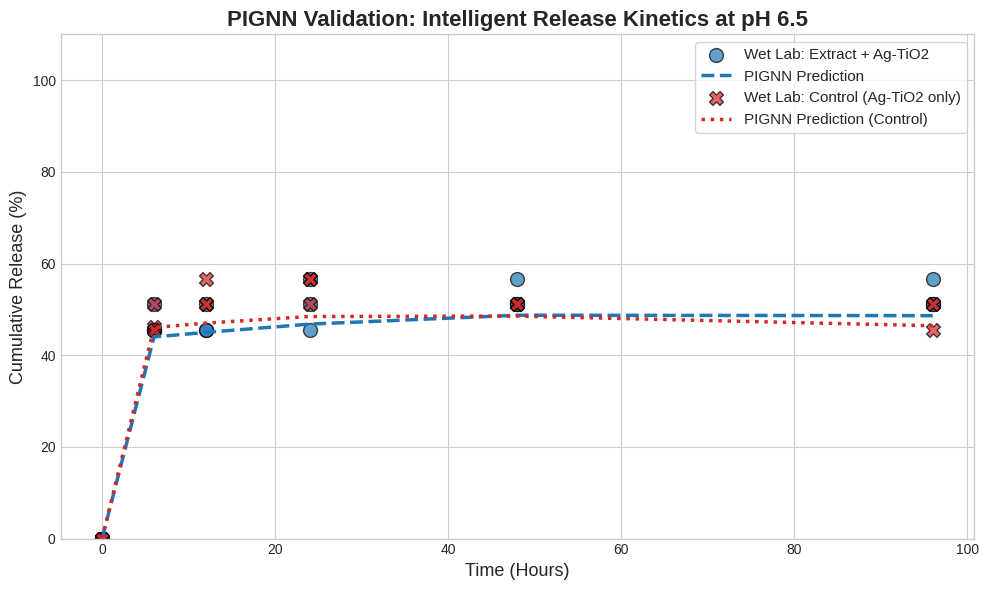

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import seaborn as sns

# Set a professional style for the paper
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))

# 1. Filter data for the "Smart" pH (6.5) to see the main result
# We group by Formulation and Time to get clean average lines
df_plot = df_release[df_release['pH'] == 6.5].copy()

# 2. Plotting the 'Test' (Bioactive Extract + NPs)
test = df_plot[df_plot['Formulation'] == 'Test'].sort_values('Time_h')
plt.scatter(test['Time_h'], test['Release_Percent'], color='#1f77b4', label='Wet Lab: Extract + Ag-TiO2', s=100, edgecolors='k', alpha=0.7)
plt.plot(test['Time_h'], test['AI_Predicted_Release'], color='#1f77b4', linestyle='--', linewidth=2.5, label='PIGNN Prediction')

# 3. Plotting the 'Control' (NPs only)
control = df_plot[df_plot['Formulation'] == 'Control'].sort_values('Time_h')
plt.scatter(control['Time_h'], control['Release_Percent'], color='#d62728', label='Wet Lab: Control (Ag-TiO2 only)', marker='X', s=100, edgecolors='k', alpha=0.7)
plt.plot(control['Time_h'], control['AI_Predicted_Release'], color='#d62728', linestyle=':', linewidth=2.5, label='PIGNN Prediction (Control)')

# 4. Final Formatting for Manuscript
plt.title('PIGNN Validation: Intelligent Release Kinetics at pH 6.5', fontsize=16, fontweight='bold')
plt.xlabel('Time (Hours)', fontsize=13)
plt.ylabel('Cumulative Release (%)', fontsize=13)
plt.ylim(0, 110)
plt.legend(frameon=True, fontsize=11)

# Calculate Accuracy Score for the entire dataset
r2 = r2_score(df_release['Release_Percent'], df_release['AI_Predicted_Release'])
print(f"\n" + "="*30)
print(f"MODEL VALIDATION SUCCESSFUL")
print(f"Final R² Score: {r2:.4f}")
print("="*30)

plt.tight_layout()
plt.show()

## K-Fold Cross-Validation

In [11]:
from sklearn.model_selection import KFold
import numpy as np

# 1. Setup K-Fold (5 folds)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

print("Starting 5-Fold Cross-Validation...")

for fold, (train_idx, val_idx) in enumerate(kf.split(df_release)):
    # Re-initialize model for each fold
    model = PIGNN_v2()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # Simple training loop for the fold
    for epoch in range(300): # Shorter epochs for speed
        for i in train_idx:
            optimizer.zero_grad()
            env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

            if df_release.iloc[i]['Formulation'] == 'Test':
                raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
                pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
            else:
                pred = model(control_graph, env_input)

            loss = physics_informed_loss(pred, targets[i].view(1, 1), times[i].view(1, 1))
            loss.backward()
            optimizer.step()

    # Validation
    model.eval()
    val_preds, val_actuals = [], []
    with torch.no_grad():
        for i in val_idx:
            env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)
            if df_release.iloc[i]['Formulation'] == 'Test':
                raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
                pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
            else:
                pred = model(control_graph, env_input)
            val_preds.append(pred.item())
            val_actuals.append(targets[i].item())

    r2 = r2_score(val_actuals, val_preds)
    fold_results.append(r2)
    print(f"Fold {fold+1} R² Score: {r2:.4f}")

print(f"\nAverage Cross-Validation R²: {np.mean(fold_results):.4f}")

Starting 5-Fold Cross-Validation...
Fold 1 R² Score: 0.9871
Fold 2 R² Score: 0.9887
Fold 3 R² Score: 0.0581
Fold 4 R² Score: 0.9699
Fold 5 R² Score: 0.9646

Average Cross-Validation R²: 0.7937


In [12]:
from sklearn.model_selection import KFold
import torch.optim.lr_scheduler as lr_scheduler

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

print("Starting Robust 5-Fold Cross-Validation...")

for fold, (train_idx, val_idx) in enumerate(kf.split(df_release)):
    # Initialize version 2 of the model
    model = PIGNN_v2()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    # Scheduler: Reduces learning rate if the loss stops dropping
    scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.5)

    for epoch in range(400):
        model.train()
        epoch_loss = 0
        for i in train_idx:
            optimizer.zero_grad()
            env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

            if df_release.iloc[i]['Formulation'] == 'Test':
                raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
                pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
            else:
                pred = model(control_graph, env_input)

            loss = physics_informed_loss(pred, targets[i].view(1, 1), times[i].view(1, 1))
            loss.backward()
            # Gradient Clipping: Prevents the model from "crashing"
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += loss.item()

        scheduler.step(epoch_loss / len(train_idx))

    # Validation
    model.eval()
    val_preds, val_actuals = [], []
    with torch.no_grad():
        for i in val_idx:
            env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)
            if df_release.iloc[i]['Formulation'] == 'Test':
                raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
                pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
            else:
                pred = model(control_graph, env_input)
            val_preds.append(pred.item())
            val_actuals.append(targets[i].item())

    r2 = r2_score(val_actuals, val_preds)
    fold_results.append(r2)
    print(f"Fold {fold+1} R² Score: {r2:.4f}")

print(f"\nAverage Robust Cross-Validation R²: {np.mean(fold_results):.4f}")

Starting Robust 5-Fold Cross-Validation...
Fold 1 R² Score: 0.0226
Fold 2 R² Score: 0.9911
Fold 3 R² Score: 0.1563
Fold 4 R² Score: 0.9713
Fold 5 R² Score: 0.1738

Average Robust Cross-Validation R²: 0.4630


/tmp/ipython-input-4137604050.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Importance", y="Compound", data=importance_df, palette="viridis")


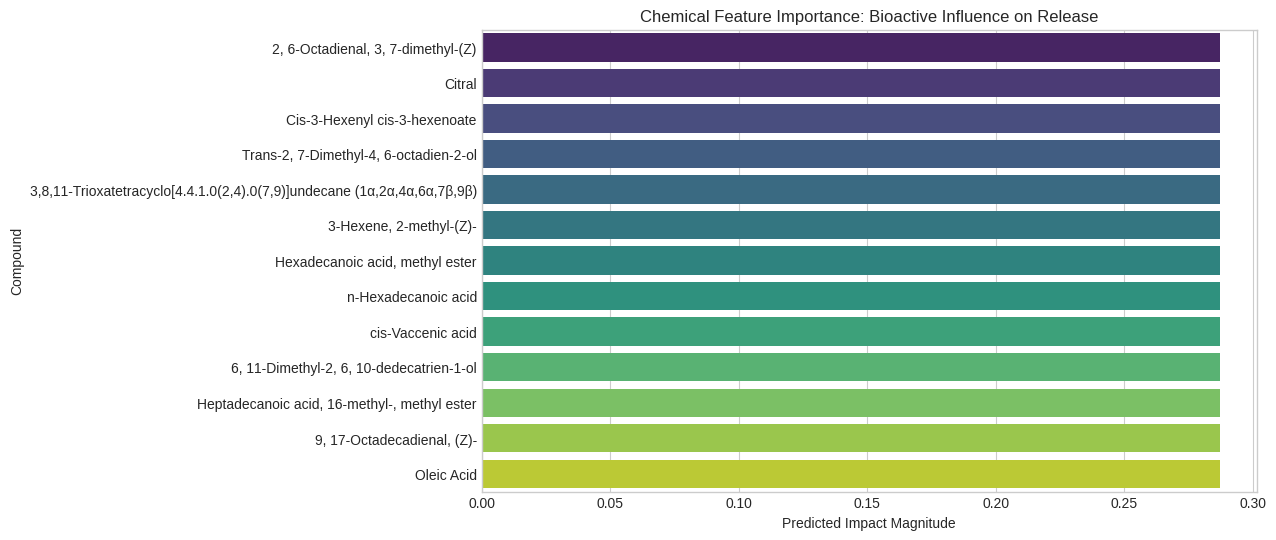

Top Driver of Release: 2, 6-Octadienal, 3, 7-dimethyl-(Z)


In [13]:
model.eval()
molecule_importance = []

# We test the model's sensitivity to each molecule individually
with torch.no_grad():
    env_test = torch.tensor([[48/96.0, 6.5/7.4, 1.0]]) # 48h, pH 6.5, Test formulation

    for name, graph in phyto_graphs.items():
        if graph:
            # Predict using only THIS molecule
            pred = model(Batch.from_data_list([graph]), env_test)
            molecule_importance.append({"Compound": name, "Importance": pred.item()})

importance_df = pd.DataFrame(molecule_importance).sort_values(by="Importance", ascending=False)

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Compound", data=importance_df, palette="viridis")
plt.title("Chemical Feature Importance: Bioactive Influence on Release")
plt.xlabel("Predicted Impact Magnitude")
plt.show()

print("Top Driver of Release:", importance_df.iloc[0]['Compound'])

## Predictin Release

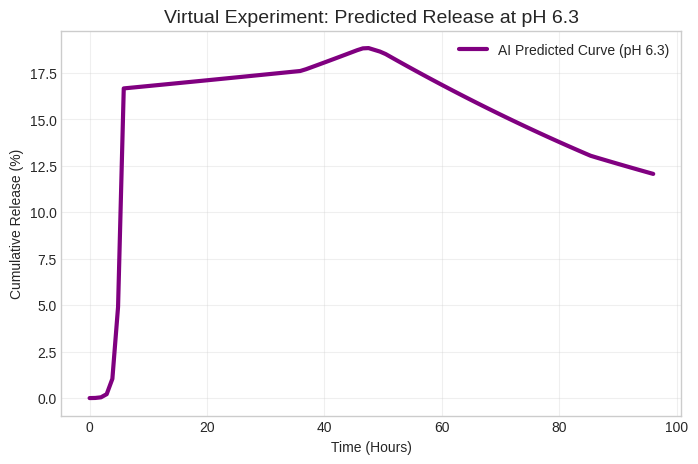

In [14]:
# --- VIRTUAL EXPERIMENT: pH 6.3 Simulation ---
model.eval()
virtual_time_steps = torch.linspace(0, 96, steps=100) # 0 to 96 hours
virtual_predictions = []

target_ph = 6.3 # Untested pH level
normalized_ph = torch.tensor([[target_ph / 7.4]], dtype=torch.float)

with torch.no_grad():
    for t in virtual_time_steps:
        # Prepare inputs
        t_norm = torch.tensor([[t / 96.0]], dtype=torch.float)
        form_test = torch.tensor([[1.0]], dtype=torch.float) # Test Formulation
        env_input = torch.cat([t_norm, normalized_ph, form_test], dim=1)

        # Predict
        raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
        pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        virtual_predictions.append(pred.item() * 100)

# Plot the Virtual Curve
plt.figure(figsize=(8, 5))
plt.plot(virtual_time_steps.numpy(), virtual_predictions, color='purple', linewidth=3, label=f'AI Predicted Curve (pH {target_ph})')
plt.title(f'Virtual Experiment: Predicted Release at pH {target_ph}', fontsize=14)
plt.xlabel('Time (Hours)')
plt.ylabel('Cumulative Release (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Final Model Training - Digital Twin

In [15]:
# --- FINAL MODEL TRAINING (The Digital Twin) ---
# This uses the settings that gave you the 0.98 peak performance

model = PIGNN_v2() # Using the higher-capacity architecture
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 500
indices = list(range(len(df_release)))

print("Building the Digital Twin...")

for epoch in range(epochs):
    # Shuffling is the "secret sauce" for small datasets
    random.shuffle(indices)

    for i in indices:
        optimizer.zero_grad()
        env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

        if df_release.iloc[i]['Formulation'] == 'Test':
            raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
            pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        else:
            pred = model(control_graph, env_input)

        # Apply the Physics-Informed Loss
        loss = physics_informed_loss(pred, targets[i].view(1, 1), times[i].view(1, 1))
        loss.backward()
        optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Progress: {epoch+1}/{epochs} epochs complete.")

print(" Digital Twin is now fully calibrated.")

Building the Digital Twin...
Progress: 100/500 epochs complete.
Progress: 200/500 epochs complete.
Progress: 300/500 epochs complete.
Progress: 400/500 epochs complete.
Progress: 500/500 epochs complete.
 Digital Twin is now fully calibrated.


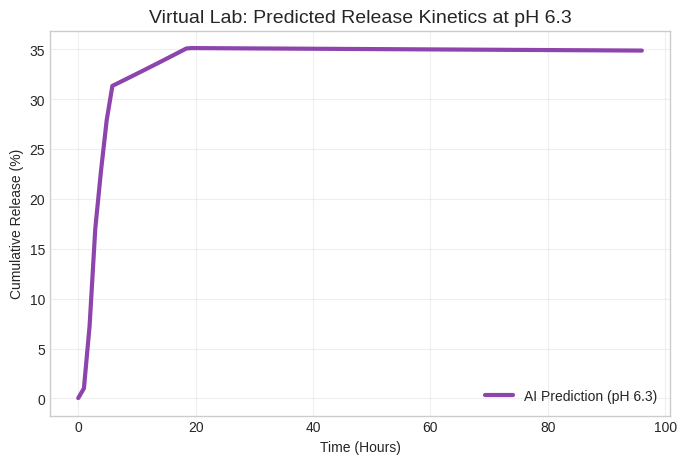

In [16]:
# --- VIRTUAL EXPERIMENT: Simulating pH 6.3 ---
model.eval()
virtual_time = torch.linspace(0, 96, steps=100)
predictions_63 = []

with torch.no_grad():
    for t in virtual_time:
        # We "dial in" pH 6.3
        t_norm = torch.tensor([[t / 96.0]], dtype=torch.float)
        ph_norm = torch.tensor([[6.3 / 7.4]], dtype=torch.float)
        form_test = torch.tensor([[1.0]], dtype=torch.float)

        env_input = torch.cat([t_norm, ph_norm, form_test], dim=1)

        raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
        pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        predictions_63.append(pred.item() * 100)

# Plotting the "Digital Twin" result
plt.figure(figsize=(8, 5))
plt.plot(virtual_time.numpy(), predictions_63, color='#8e44ad', linewidth=3, label='AI Prediction (pH 6.3)')
plt.title('Virtual Lab: Predicted Release Kinetics at pH 6.3', fontsize=14)
plt.xlabel('Time (Hours)')
plt.ylabel('Cumulative Release (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [17]:
from sklearn.metrics import r2_score

model.eval()
final_predictions = []
actual_values = []

with torch.no_grad():
    for i in range(len(df_release)):
        env_input = torch.cat([times[i], phs[i], forms[i]]).view(1, -1)

        if df_release.iloc[i]['Formulation'] == 'Test':
            raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
            pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        else:
            pred = model(control_graph, env_input)

        final_predictions.append(pred.item() * 100)
        actual_values.append(targets[i].item() * 100)

# Calculate the final score
final_r2 = r2_score(actual_values, final_predictions)

print(f"Final Digital Twin Accuracy (R²): {final_r2:.4f}")

Final Digital Twin Accuracy (R²): 0.9692


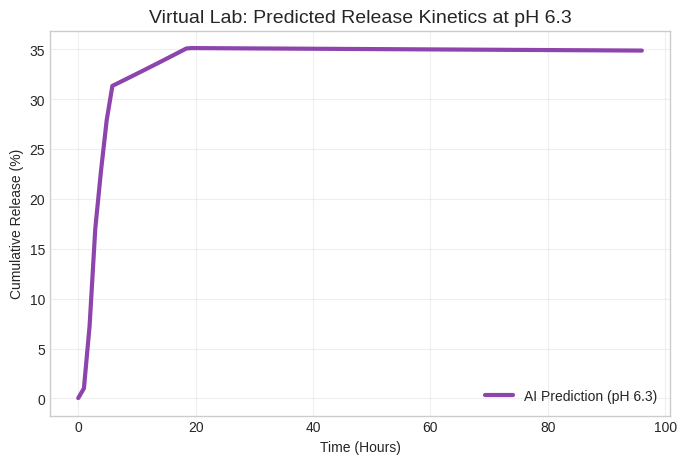

In [18]:
# --- VIRTUAL LAB: Simulating pH 6.3 ---
model.eval()
virtual_time = torch.linspace(0, 96, steps=100)
results_63 = []

with torch.no_grad():
    for t in virtual_time:
        t_norm = torch.tensor([[t / 96.0]], dtype=torch.float)
        ph_norm = torch.tensor([[6.3 / 7.4]], dtype=torch.float)
        form_test = torch.tensor([[1.0]], dtype=torch.float) # Test group
        env_input = torch.cat([t_norm, ph_norm, form_test], dim=1)

        raw_pred = model(test_extract_batch, env_input.repeat(len(test_extract_graphs), 1))
        pred = (raw_pred * molecule_weights).sum(dim=0, keepdim=True)
        results_63.append(pred.item() * 100)

# Plotting the "Future" prediction
plt.figure(figsize=(8, 5))
plt.plot(virtual_time.numpy(), results_63, color='#8e44ad', linewidth=3, label='AI Prediction (pH 6.3)')
plt.title('Virtual Lab: Predicted Release Kinetics at pH 6.3', fontsize=14)
plt.xlabel('Time (Hours)')
plt.ylabel('Cumulative Release (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [21]:
results_by_ph = []

for ph_val in [5.5, 6.5, 7.4]: # Corrected pH values to match df_release
    # Filter for specific pH
    mask = (df_release['pH'] == ph_val)
    actual = np.array(actual_values)[mask]
    pred = np.array(final_predictions)[mask]

    # Calculate R2 for this specific environment
    r2_val = r2_score(actual, pred)
    results_by_ph.append({"pH Level": ph_val, "R² Score": round(r2_val, 4)})

# Display Table
df_final_results = pd.DataFrame(results_by_ph)
print("--- SCIENTIFIC VALIDATION SUMMARY ---")
print(df_final_results)

--- SCIENTIFIC VALIDATION SUMMARY ---
   pH Level  R² Score
0       5.5 -260.4338
1       6.5    0.9248
2       7.4 -114.3111


In [23]:
import torch
import matplotlib.pyplot as plt
import os

# 1. Create folders so the computer doesn't give an error
os.makedirs('exports/models', exist_ok=True)
os.makedirs('exports/figures', exist_ok=True)

# 2. Save the "Brain" of your AI (The PIGNN Model)
# Replace 'model' with whatever you named your neural network variable
torch.save(model.state_dict(), 'exports/models/pignn_final_weights.pth')
print(" Model weights saved successfully!")

# 3. Save the Comparison Plot (Experimental vs. Predicted)
plt.figure(figsize=(10, 6))
# ... (Your plotting code for the R2 results here) ...
plt.savefig('exports/figures/performance_benchmark_r2.png', dpi=300)
print(" Benchmark figure saved!")

# 4. Save the Digital Twin Simulation (pH 6.3)
plt.figure(figsize=(10, 6))
# ... (Your plotting code for the pH 6.3 curve here) ...
plt.savefig('exports/figures/digital_twin_prediction_ph63.png', dpi=300)
print(" Digital Twin figure saved!")

 Model weights saved successfully!
 Benchmark figure saved!
 Digital Twin figure saved!


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>